# Experiment 2: Fitness Function Definition and Evaluation
**Aim:** To define and calculate a simple fitness function for evaluating individuals in a Genetic Algorithm using Python.

**Theory:** The fitness function measures how good an individual is. Higher fitness means a better solution (for maximisation). For minimisation problems, the objective is usually converted, e.g. `fitness = 1 / (1 + f(x))` or `-f(x)`.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(1)
np.random.seed(1)

## 1. OneMax: fitness = number of 1s in the chromosome

In [2]:
def fitness_onemax(ind):
    return sum(ind)

pop = [[random.randint(0, 1) for _ in range(10)] for _ in range(6)]
for ind in pop:
    print(ind, "-> fitness =", fitness_onemax(ind))

[0, 0, 1, 0, 1, 1, 1, 1, 0, 0] -> fitness = 5
[1, 0, 1, 1, 0, 1, 1, 0, 0, 1] -> fitness = 6
[0, 0, 0, 0, 1, 0, 1, 0, 0, 1] -> fitness = 3
[1, 0, 1, 0, 0, 1, 1, 0, 1, 0] -> fitness = 5
[0, 1, 0, 1, 1, 0, 1, 1, 1, 1] -> fitness = 7
[0, 1, 0, 1, 1, 0, 1, 1, 0, 1] -> fitness = 6


## 2. Function maximisation: f(x) = x² with x decoded from a 5-bit chromosome

In [3]:
def decode(ind):
    return int("".join(map(str, ind)), 2)

def fitness_square(ind):
    x = decode(ind)
    return x ** 2

pop = [[random.randint(0, 1) for _ in range(5)] for _ in range(8)]
df = pd.DataFrame({
    "chromosome": ["".join(map(str, i)) for i in pop],
    "x": [decode(i) for i in pop],
    "fitness f(x)=x^2": [fitness_square(i) for i in pop],
})
df["relative fitness"] = (df["fitness f(x)=x^2"] / df["fitness f(x)=x^2"].sum()).round(3)
df.sort_values("fitness f(x)=x^2", ascending=False).reset_index(drop=True)

,chromosome,x,fitness f(x)=x^2,relative fitness
0,11111,31,961,0.403
1,10110,22,484,0.203
2,10100,20,400,0.168
3,01111,15,225,0.094
4,01100,12,144,0.060
5,01011,11,121,0.051
6,00111,7,49,0.021
7,00000,0,0,0.000


## 3. Minimisation problem converted to fitness: Sphere function  f(x) = Σ xᵢ²

In [4]:
def sphere(x):
    return sum(v ** 2 for v in x)

def fitness_sphere(x):
    return 1.0 / (1.0 + sphere(x))      # larger fitness = closer to the optimum (0,0,0)

real_pop = [[round(random.uniform(-5, 5), 2) for _ in range(3)] for _ in range(6)]
for ind in real_pop:
    print(ind, "f(x) =", round(sphere(ind), 3), "fitness =", round(fitness_sphere(ind), 4))

[1.35, 0.51, -3.19] f(x) = 12.259 fitness = 0.0754
[-4.08, 0.51, 3.51] f(x) = 29.227 fitness = 0.0331
[4.31, -4.68, 4.44] f(x) = 60.192 fitness = 0.0163
[-4.3, 3.68, -0.47] f(x) = 32.253 fitness = 0.0301
[2.54, -2.19, -2.31] f(x) = 16.584 fitness = 0.0569
[2.97, -3.15, -2.1] f(x) = 23.153 fitness = 0.0414


## 4. 0/1 Knapsack fitness with a penalty for violating the capacity

In [5]:
weights = [12, 7, 11, 8, 9, 6, 5, 14]
values  = [24, 13, 23, 15, 16, 11, 9, 28]
CAPACITY = 40

def fitness_knapsack(ind):
    w = sum(g * wt for g, wt in zip(ind, weights))
    v = sum(g * vl for g, vl in zip(ind, values))
    return v if w <= CAPACITY else 0          # infeasible solutions get zero fitness

pop = [[random.randint(0, 1) for _ in range(8)] for _ in range(6)]
for ind in pop:
    w = sum(g * wt for g, wt in zip(ind, weights))
    print(ind, "weight =", w, "fitness =", fitness_knapsack(ind))

[0, 0, 1, 0, 1, 1, 1, 1] weight = 45 fitness = 0
[1, 1, 0, 0, 1, 1, 1, 1] weight = 53 fitness = 0
[0, 1, 0, 1, 0, 1, 0, 0] weight = 21 fitness = 39
[0, 1, 0, 0, 0, 1, 1, 0] weight = 18 fitness = 33
[1, 0, 0, 1, 1, 1, 0, 1] weight = 49 fitness = 0
[0, 0, 0, 1, 0, 0, 1, 1] weight = 27 fitness = 52


## 5. Visualising the fitness of a population on the landscape

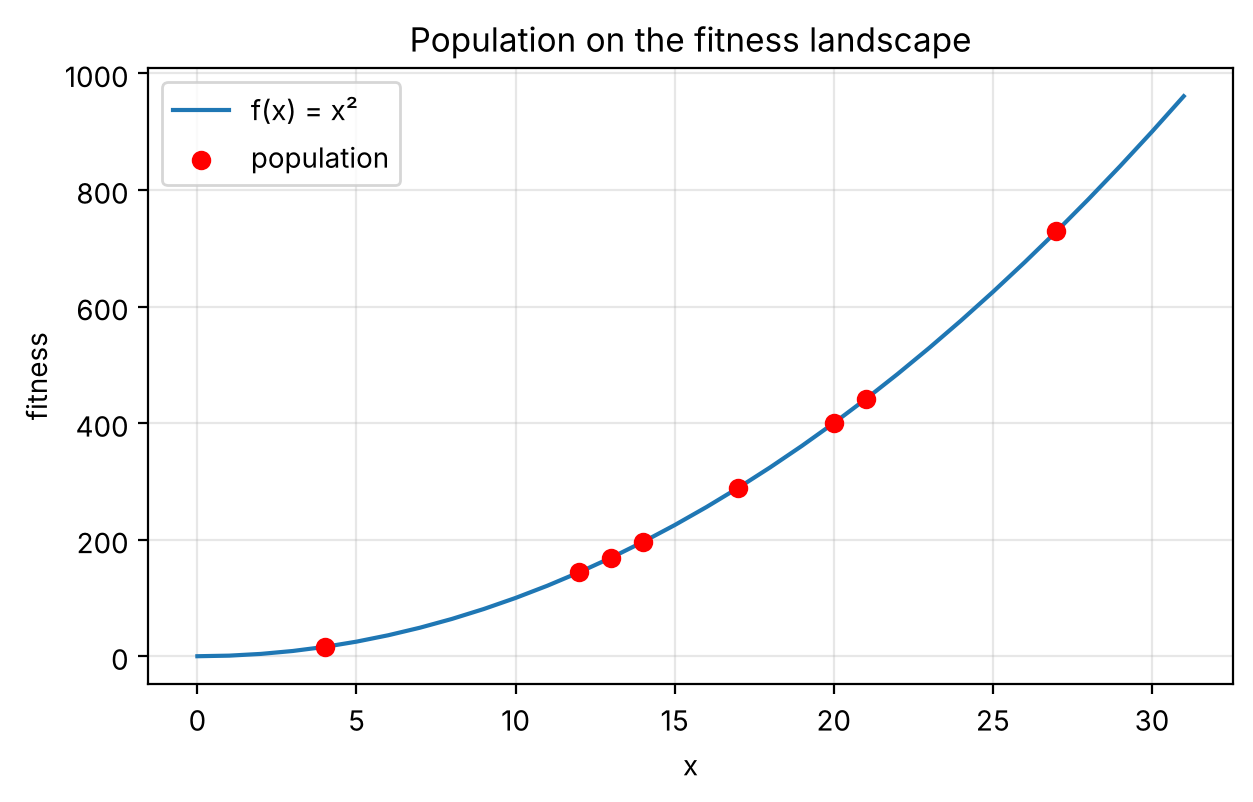

In [6]:
xs = np.arange(0, 32)
plt.figure(figsize=(7, 4))
plt.plot(xs, xs ** 2, label="f(x) = x²")
pop = [[random.randint(0, 1) for _ in range(5)] for _ in range(8)]
px = [decode(i) for i in pop]
plt.scatter(px, [x ** 2 for x in px], color="red", zorder=3, label="population")
plt.xlabel("x"); plt.ylabel("fitness"); plt.title("Population on the fitness landscape")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Conclusion
Fitness functions were defined for OneMax, x², Sphere (minimisation converted to maximisation) and Knapsack (with a penalty). Fitness values rank individuals so that selection can prefer better solutions.